### Proof of Concept for Machine Learning classification of coconuts oils based on spectroscopic data

If you are not the owner of this Jupyter notebook, please do not touch. Running this notebook takes at least 25 minutes if run locally.

**Table 1. Identifying the Chemical Basis of Differentiating VCO from RBDCO**  
*Table generated by ChatGPT 5.2.*

| Spectroscopic Method | Spectroscopic Signal Index | Rationale | Signal Index could be higher in... | Separability of VCO and RBDCO |
|---|---|---|---|---|
| UV-Vis | Absorbance at 278 nm | UV-absorbing heat transformation products formed while making RBDCO increase absorbance at 278 nm<sup>1</sup>. | RBDCO | Separable |
| <sup>13</sup>C NMR | 1,3-Diglyceride Signal Ratio | Higher concentration of 1,3-diglycerides in RBDCO than in VCO<sup>2-3</sup> | RBDCO | Separable |
| <sup>1</sup>H NMR | Allylic H signal ratio | <sup>1</sup>H NMR can compare the amount of unsaturated fatty acids between food oils, especially using the sum of signals in the allylic region<sup>3-5</sup>. This has been demonstrated using coconut oil and palm oil<sup>6</sup>. | Neither | Not sufficiently established |


In [3]:
## Import libraries
## !pip install shap
## !pip install sigfig

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, f1_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn import tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier
import shap

In [4]:
coconut_3_features = pd.read_csv("VCO project Dr Dayrit dataset August 25.csv")

coconut_ML = coconut_3_features.copy()

coconut_train = coconut_ML[~coconut_ML["Sample"].str.contains(r"VCO")]
coconut_test = coconut_ML[coconut_ML["Sample"].str.contains(r"VCO")]

vco = coconut_ML[coconut_ML["IsVCO"] == 1]
rbdco = coconut_ML[coconut_ML["IsVCO"] == 0]

First, we do an exploratory data analysis, using descriptive statistics and boxplots.

In [5]:
## UV-Vis absorbances
vco_mean_absorbance_278 = np.mean(vco["Absorbance (278 nm)"])
vco_standev_absorbance_278 = np.std(vco["Absorbance (278 nm)"])

rbdco_mean_absorbance_278 = np.mean(rbdco["Absorbance (278 nm)"])
rbdco_standev_absorbance_278 = np.std(rbdco["Absorbance (278 nm)"])

## 13C NMR Diglyceride signal intensities
vco_13C_diglycerides_mean = np.mean(vco["1,3-Diglyceride Signal Ratio"])
vco_13C_diglycerides_std = np.std(vco["1,3-Diglyceride Signal Ratio"])

rbdco_13C_diglycerides_mean = np.mean(rbdco["1,3-Diglyceride Signal Ratio"])
rbdco_13C_diglycerides_std = np.std(rbdco["1,3-Diglyceride Signal Ratio"])

## proton NMR Summed signal intensities at the allylic peak
vco_proton_allylic_hydrogen_mean = np.mean(vco["Allylic Hydrogen Signal Ratio"])
vco_proton_allylic_hydrogen_std = np.std(vco["Allylic Hydrogen Signal Ratio"])

rbdco_proton_allylic_hydrogen_mean = np.mean(rbdco["Allylic Hydrogen Signal Ratio"])
rbdco_proton_allylic_hydrogen_std = np.std(rbdco["Allylic Hydrogen Signal Ratio"])


## Test statistics—use unequal variance, as the oil making processes are different.
t_UV_278, p_UV_278 = stats.ttest_ind(vco["Absorbance (278 nm)"], rbdco["Absorbance (278 nm)"], equal_var = False, alternative = "less")
t_13C_diglycerides, p_13C_diglycerides = stats.ttest_ind(vco["1,3-Diglyceride Signal Ratio"], rbdco["1,3-Diglyceride Signal Ratio"], equal_var = False, alternative = "less")
t_proton_allylic_hydrogen, p_proton_allylic_hydrogen = stats.ttest_ind(vco["Allylic Hydrogen Signal Ratio"], rbdco["Allylic Hydrogen Signal Ratio"], equal_var = False)

In [6]:
descriptive_statistics = pd.DataFrame({
    "Spectroscopic Characteristic": ["Absorbance at 278 nm",
                                     "1,3-Diglyceride Signal Ratio",
                                     "Allylic Hydrogen Signal Ratio"],
    
    "VCO (Mean ± St. Dev)": [f"{round(vco_mean_absorbance_278, 3)} ± {round(vco_standev_absorbance_278, 3)}",
             f"{vco_13C_diglycerides_mean:.3e} ± {vco_13C_diglycerides_std:.3e}",
             f"{round(vco_proton_allylic_hydrogen_mean, 3)} ± {round(vco_proton_allylic_hydrogen_std, 3)}"],
    
    "RBDCO (Mean ± St. Dev)": [f"{round(rbdco_mean_absorbance_278, 3)} ± {round(rbdco_standev_absorbance_278, 3)}",
             f"{rbdco_13C_diglycerides_mean:.3e} ± {rbdco_13C_diglycerides_std:.3e}",
             f"{round(rbdco_proton_allylic_hydrogen_mean, 3)} ± {round(rbdco_proton_allylic_hydrogen_std, 3)}"],

    "p-Value": [p_UV_278,
                p_13C_diglycerides,
                p_proton_allylic_hydrogen]
})

descriptive_statistics

,Spectroscopic Characteristic,VCO (Mean ± St. Dev),RBDCO (Mean ± St. Dev),p-Value
0,Absorbance at 278 nm,0.783 ± 0.303,3.382 ± 0.2,2.751181e-39
1,"1,3-Diglyceride Signal Ratio",7.675e-03 ± 1.769e-03,1.099e-02 ± 1.791e-03,6.666644e-08
2,Allylic Hydrogen Signal Ratio,0.072 ± 0.008,0.092 ± 0.006,1.386440e-13


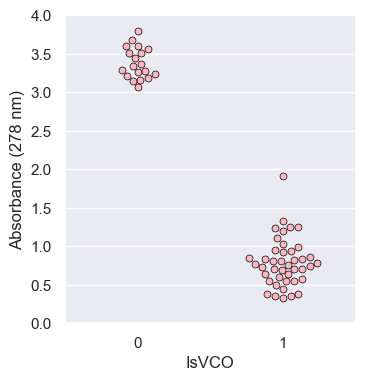

In [8]:
sns.swarmplot(data = coconut_train, x = "IsVCO", y = "Absorbance (278 nm)", color = '#ffb7c2', edgecolor = 'black', linewidth = 0.5)
sns.set_theme(rc={"figure.figsize": (3.75, 4)})
plt.ylim(0, 4)
plt.show()

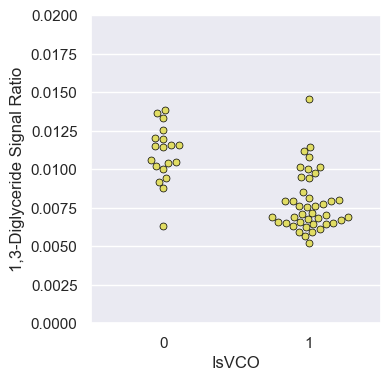

In [9]:
sns.swarmplot(x = "IsVCO", y = "1,3-Diglyceride Signal Ratio", data = coconut_train, color = '#e1dd64',  edgecolor = 'black', linewidth = 0.5)
sns.set_theme(rc={"figure.figsize": (3.75, 4)})
plt.ylim(0, 0.02)
plt.show()

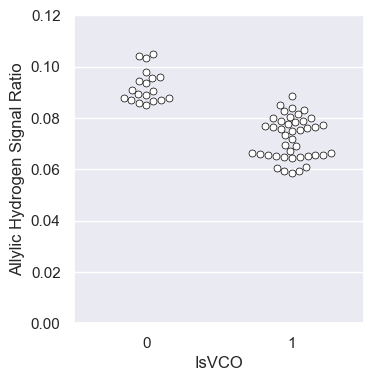

In [11]:
sns.swarmplot(x = "IsVCO", y = "Allylic Hydrogen Signal Ratio", data = coconut_train, color = 'white', edgecolor = 'black', linewidth = 0.5)
sns.set_theme(rc={"figure.figsize": (3.75, 4)})
plt.ylim(0, 0.12)
plt.show()

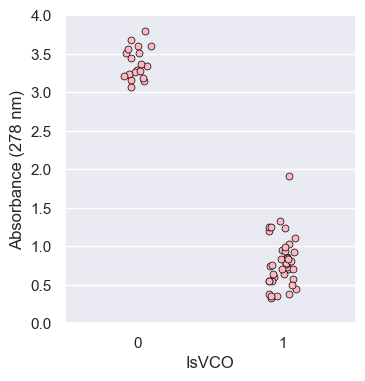

In [12]:
sns.stripplot(data = coconut_train, x = "IsVCO", y = "Absorbance (278 nm)", color = '#ffb7c2', edgecolor = 'black', linewidth = 0.5)
sns.set_theme(rc={"figure.figsize": (2, 4)})
plt.ylim(0, 4)
plt.show()

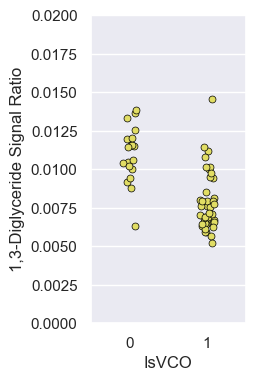

In [13]:
sns.stripplot(x = "IsVCO", y = "1,3-Diglyceride Signal Ratio", data = coconut_train, color = '#e1dd64',  edgecolor = 'black', linewidth = 0.5)
sns.set_theme(rc={"figure.figsize": (2, 4)})
plt.ylim(0, 0.02)
plt.show()

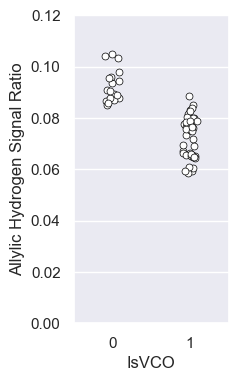

In [14]:
sns.stripplot(x = "IsVCO", y = "Allylic Hydrogen Signal Ratio", data = coconut_train, color = 'white', edgecolor = 'black', linewidth = 0.5)
sns.set_theme(rc={"figure.figsize": (2, 4)})
plt.ylim(0, 0.12)
plt.show()

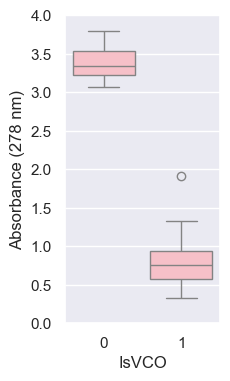

In [15]:
sns.boxplot(x = "IsVCO", y = "Absorbance (278 nm)", data = coconut_train, color = '#ffb7c2')
sns.set_theme(rc={"figure.figsize": (2, 4)})
plt.ylim(0, 4)
plt.show()

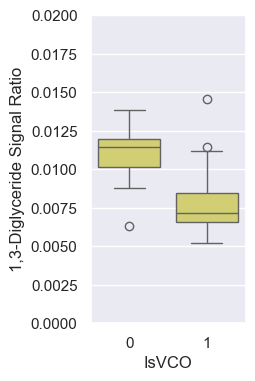

In [16]:
sns.boxplot(x = "IsVCO", y = "1,3-Diglyceride Signal Ratio", data = coconut_train, color = '#e1dd64')
sns.set_theme(rc={"figure.figsize": (2, 4)})
plt.ylim(0, 0.02)
plt.show()

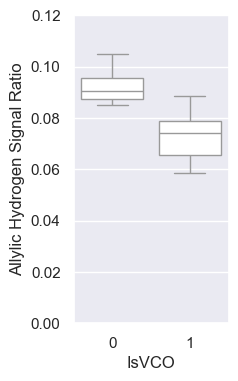

In [17]:
sns.boxplot(x = "IsVCO", y = "Allylic Hydrogen Signal Ratio", data = coconut_train, color = 'white')
sns.set_theme(rc={"figure.figsize": (2, 4)})
plt.ylim(0, 0.12)
plt.show()

<Axes: >

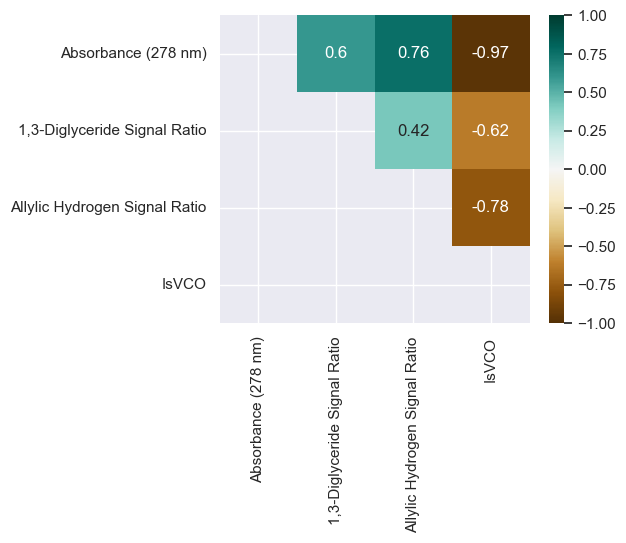

In [18]:
coconut_corr = coconut_train.drop(["Sample", "Control Code"], axis = 1).corr().round(2)
mask = np.tril(np.ones_like(coconut_corr, dtype = bool))

sns.set_theme(rc={"figure.figsize": (5, 4)})
sns.heatmap(coconut_corr, annot = True, mask = mask, vmin = -1, vmax = 1, cmap = "BrBG")


In [19]:
X = coconut_train.drop(["Sample", "Control Code", "IsVCO"], axis = 1)

vif_data = pd.DataFrame()
vif_data["Predictor"] = X.columns

vif_data["VIF"] = [variance_inflation_factor(X.values, i)
                          for i in range(len(X.columns))]
print(vif_data)

                       Predictor        VIF
0            Absorbance (278 nm)   3.924690
1   1,3-Diglyceride Signal Ratio  18.763717
2  Allylic Hydrogen Signal Ratio  17.974271


Best parameter set for decision tree: {'criterion': 'gini'}
Best cross validation score for decision tree: 97.5%


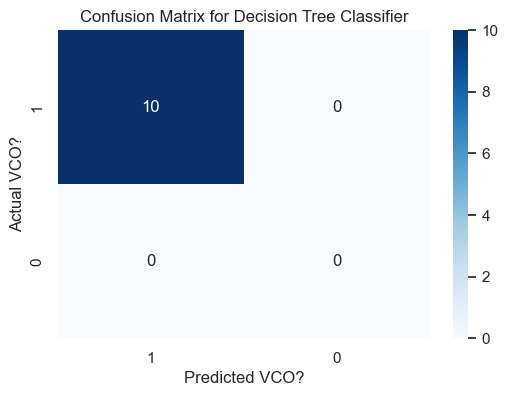

Recall for DT Classifier: 100.0%
F1-score for DT Classifier: 100.0%


In [20]:
features_to_drop = ["Sample", "Control Code", "IsVCO"]

X_dt_train = coconut_train.drop(features_to_drop, axis = 1)
y_dt_train = coconut_train["IsVCO"]
X_dt_test = coconut_test.drop(features_to_drop, axis = 1)
y_dt_test = coconut_test["IsVCO"]

dec_tree = DecisionTreeClassifier(random_state = 42)
skf_cv = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 42)

param_grid_dt = {
    "criterion":["gini", "entropy"]
}

grid_search_dt = GridSearchCV(
    estimator = dec_tree,
    param_grid = param_grid_dt,
    scoring = "f1",
    cv = skf_cv,
    n_jobs = 3
)

grid_search_dt.fit(X_dt_train, y_dt_train)
best_dt_model = grid_search_dt.best_estimator_

print(f"Best parameter set for decision tree: {grid_search_dt.best_params_}")
print(f"Best cross validation score for decision tree: {round(grid_search_dt.best_score_*100, 2)}%")
## All decision trees here converge to one decision stump.

y_pred = best_dt_model.predict(X_dt_test)
cm = confusion_matrix(y_dt_test, y_pred, labels = [1, 0])
classes = [1, 0]
plt.figure(figsize=(6, 4))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)

plt.xlabel("Predicted VCO?")
plt.ylabel("Actual VCO?")
plt.title("Confusion Matrix for Decision Tree Classifier")
plt.show()


## Assumes that we already made a confusion matrix
def performance_metrics(conf_matrix):
    true_positive = conf_matrix[0][0]
    false_positive = conf_matrix[1][0]
    false_negative = conf_matrix[0][1]

    
    precision = 100 * (true_positive) / (true_positive + false_positive) if (true_positive + false_positive) > 0 else 0
    recall = 100 * (true_positive) / (true_positive + false_negative) if (true_positive + false_negative) > 0 else 0
    f1_score = 2 / ((1/precision) + (1/recall)) if (precision > 0 or recall > 0) else 0
    
    return precision, recall, f1_score


print(f"Recall for DT Classifier: {round(performance_metrics(cm)[1], 2)}%")
print(f"F1-score for DT Classifier: {round(performance_metrics(cm)[2], 2)}%")

In [21]:
feature_importance_scores_dt = best_dt_model.feature_importances_

raw_feature_importance_scores_dt = best_dt_model.feature_importances_

table_raw_feature_importance_scores_dt = pd.DataFrame({
    "Predictor":X_dt_train.columns.tolist(),
    "Feature Importance Score (DT)":raw_feature_importance_scores_dt
})

## Normalize feature importance scores
normalized_feature_importance_scores_dt = feature_importance_scores_dt / np.sum(np.abs(feature_importance_scores_dt))

table_feature_importance_scores_dt = pd.DataFrame({
    "Predictor":X_dt_train.columns,
    "Normalized Feature Importance Metric (Dec. Tree)":normalized_feature_importance_scores_dt
}).sort_values(
    by="Normalized Feature Importance Metric (Dec. Tree)",
    ascending=False)

table_feature_importance_scores_dt

,Predictor,Normalized Feature Importance Metric (Dec. Tree)
0,Absorbance (278 nm),1.0
1,"1,3-Diglyceride Signal Ratio",0.0
2,Allylic Hydrogen Signal Ratio,0.0


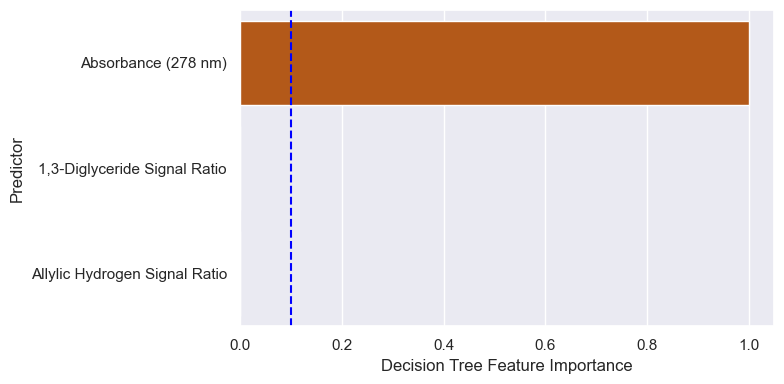

In [22]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_raw_feature_importance_scores_dt,
    x="Feature Importance Score (DT)",
    y="Predictor",
    color="#cc5500"
)

plt.xlabel("Decision Tree Feature Importance")
plt.axvline(x = 0.1, color = "blue", linestyle = "--", label = "Cutoff")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

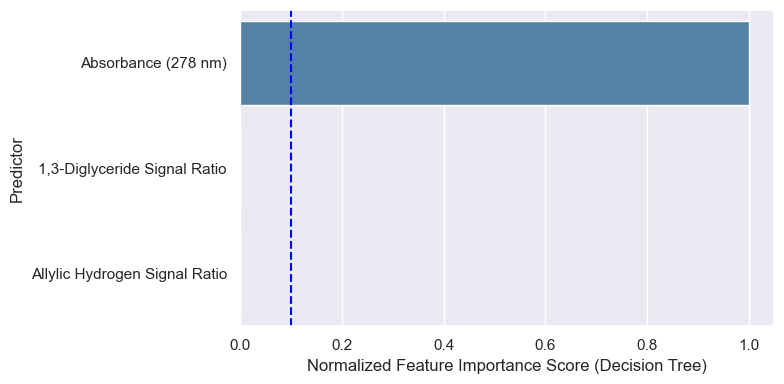

In [23]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_feature_importance_scores_dt,
    x="Normalized Feature Importance Metric (Dec. Tree)",
    y="Predictor",
    color="steelblue"
)

plt.xlabel("Normalized Feature Importance Score (Decision Tree)")
plt.axvline(x = 0.1, color = "blue", linestyle = "--", label = "Cutoff")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

[Text(0.5, 0.75, 'Absorbance (278 nm) <= 2.488\ngini = 0.429\nsamples = 61\nvalue = [19, 42]\nclass = VCO'),
 Text(0.25, 0.25, 'gini = 0.0\nsamples = 42\nvalue = [0, 42]\nclass = VCO'),
 Text(0.375, 0.5, 'True  '),
 Text(0.75, 0.25, 'gini = 0.0\nsamples = 19\nvalue = [19, 0]\nclass = RBDCO'),
 Text(0.625, 0.5, '  False')]

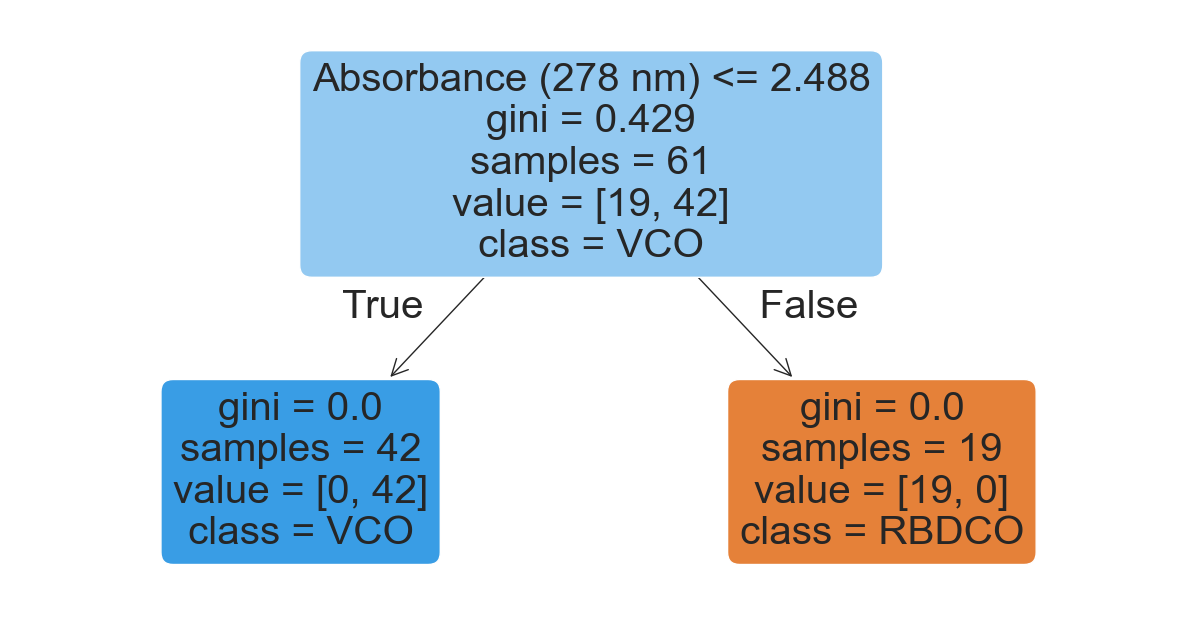

In [24]:
class_names = ["RBDCO", "VCO"]

plt.figure(figsize=(15, 8))
tree.plot_tree(
    best_dt_model,
    feature_names=X_dt_train.columns,
    class_names=class_names,
    filled=True,
    rounded=True
)

c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

Best parameters for Logistic Regression: {'C': 0.5, 'max_iter': 5, 'penalty': 'l2'}
Best Cross-Validated Accuracy: 100.0%


c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/st

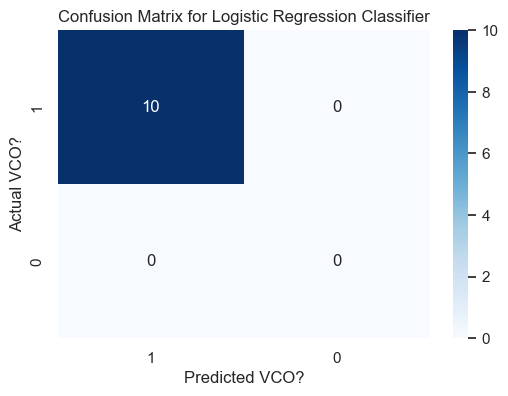

Precision for LR Classifier: 100.0%
Recall for LR Classifier: 100.0%
F1-score for LR Classifier: 100.0%


In [25]:
LR_train = coconut_train.copy()
LR_test = coconut_test.copy()

scaler_UV_278 = MinMaxScaler()
scaler_diglycerides_NMR = MinMaxScaler()
scaler_allylic_hydrogen_NMR = MinMaxScaler()


LR_train["Absorbance (278 nm)"] = scaler_UV_278.fit_transform(pd.DataFrame(LR_train["Absorbance (278 nm)"]))
LR_train["1,3-Diglyceride Signal Ratio"] = scaler_diglycerides_NMR.fit_transform(pd.DataFrame(LR_train["1,3-Diglyceride Signal Ratio"]))
#LR_train["Free Fatty Acids Signal Ratio"] = scaler_FFA_NMR.fit_transform(pd.DataFrame(LR_train["Free Fatty Acids Signal Ratio"]))
LR_train["Allylic Hydrogen Signal Ratio"] = scaler_allylic_hydrogen_NMR.fit_transform(pd.DataFrame(LR_train["Allylic Hydrogen Signal Ratio"]))

LR_test["Absorbance (278 nm)"] = scaler_UV_278.partial_fit(pd.DataFrame(LR_test["Absorbance (278 nm)"])).transform(pd.DataFrame(LR_test["Absorbance (278 nm)"]))
LR_test["1,3-Diglyceride Signal Ratio"] = scaler_diglycerides_NMR.partial_fit(pd.DataFrame(LR_test["1,3-Diglyceride Signal Ratio"])).transform(pd.DataFrame(LR_test["1,3-Diglyceride Signal Ratio"]))
#LR_test["Free Fatty Acids Signal Ratio"] = scaler_FFA_NMR.partial_fit(pd.DataFrame(LR_test["Free Fatty Acids Signal Ratio"])).transform(pd.DataFrame(LR_test["Free Fatty Acids Signal Ratio"]))
LR_test["Allylic Hydrogen Signal Ratio"] = scaler_allylic_hydrogen_NMR.partial_fit(pd.DataFrame(LR_test["Allylic Hydrogen Signal Ratio"])).transform(pd.DataFrame(LR_test["Allylic Hydrogen Signal Ratio"]))

X_lr_train = LR_train.drop(features_to_drop, axis = 1)
y_lr_train = LR_train["IsVCO"]
X_lr_test = LR_test.drop(features_to_drop, axis = 1)
y_lr_test = LR_test["IsVCO"]

logistic = LogisticRegression(random_state = 42)

param_grid_lr = {
    "penalty":["l2", "none"],
    "C":[0.5, 1, 10],
    "max_iter":[1, 2, 5, 10]
}

grid_search_lr = GridSearchCV(
    estimator = logistic,
    param_grid = param_grid_lr,
    cv = skf_cv,
    n_jobs = 1,
    scoring = "f1"
)

grid_search_lr.fit(X_lr_train, y_lr_train)

best_lr_model = grid_search_lr.best_estimator_
best_lr_params = grid_search_lr.best_params_
best_lr_score = grid_search_lr.best_score_

print(f"Best parameters for Logistic Regression: {grid_search_lr.best_params_}")
print(f"Best Cross-Validated Accuracy: {round(best_lr_score*100, 2)}%")

y_pred = best_lr_model.predict(X_lr_test)
cm_LR = confusion_matrix(y_lr_test, y_pred, labels = [1, 0])
classes = [1, 0]
plt.figure(figsize=(6, 4))

sns.heatmap(cm_LR, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted VCO?")
plt.ylabel("Actual VCO?")
plt.title("Confusion Matrix for Logistic Regression Classifier")
plt.show()

print(f"Precision for LR Classifier: {round(performance_metrics(cm_LR)[0], 2)}%")
print(f"Recall for LR Classifier: {round(performance_metrics(cm_LR)[1], 2)}%")
print(f"F1-score for LR Classifier: {round(performance_metrics(cm_LR)[2], 2)}%")

In [26]:
feature_importance_scores_lr = best_lr_model.coef_

raw_feature_importance_scores_lr = best_lr_model.coef_.ravel()

table_raw_feature_importance_scores_lr = pd.DataFrame({
    "Predictor":X_lr_train.columns.tolist(),
    "Normalized Regression Coefficients (LR)":raw_feature_importance_scores_lr
})


## Normalize feature importance scores
normalized_feature_importance_scores_lr = np.abs(feature_importance_scores_lr) / np.sum(np.abs(feature_importance_scores_lr))
normalized_feature_importance_scores_lr = normalized_feature_importance_scores_lr.ravel()

table_feature_importance_scores_lr = pd.DataFrame({
    "Predictor":X_lr_train.columns.tolist(),
    "Normalized Regression Coefficients (LR)":normalized_feature_importance_scores_lr
})

table_feature_importance_scores_lr

,Predictor,Normalized Regression Coefficients (LR)
0,Absorbance (278 nm),0.532083
1,"1,3-Diglyceride Signal Ratio",0.199527
2,Allylic Hydrogen Signal Ratio,0.268390


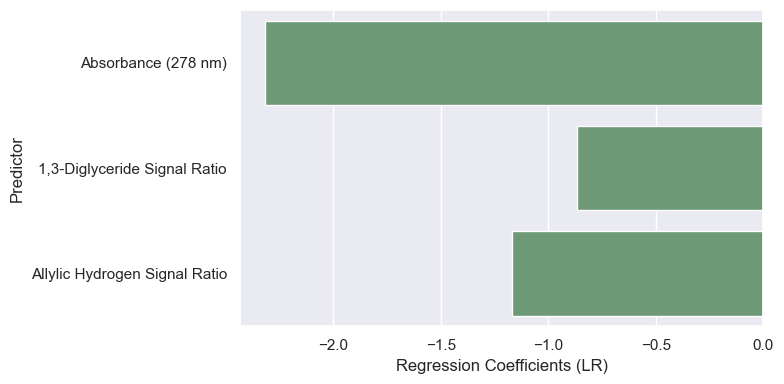

In [27]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_raw_feature_importance_scores_lr,
    x="Normalized Regression Coefficients (LR)",
    y="Predictor",
    color="#66a073"
)

plt.xlabel("Regression Coefficients (LR)")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

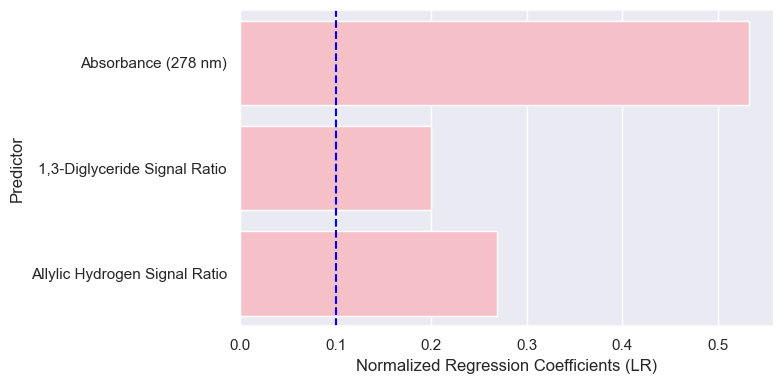

In [28]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_feature_importance_scores_lr,
    x="Normalized Regression Coefficients (LR)",
    y="Predictor",
    color="#ffb7c2"
)

plt.xlabel("Normalized Regression Coefficients (LR)")
plt.axvline(x = 0.10, color = "blue", linestyle = "--", label = "Cutoff")
plt.xticks()
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

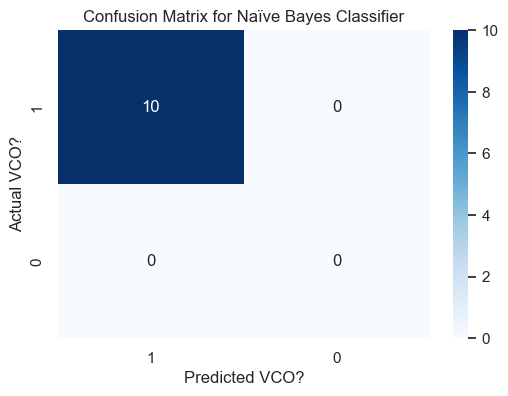

Precision for Naïve Bayes Classifier : 100.0%
Recall for Naïve Bayes Classifier : 100.0%
F1-Score for Naïve Bayes Classifier : 100.0%


In [29]:
X_train_NB = coconut_train.drop(features_to_drop, axis = 1)
y_train_NB = coconut_train["IsVCO"]
X_test_NB = coconut_test.drop(features_to_drop, axis = 1)
y_test_NB = coconut_test["IsVCO"]

naive_bayes = GaussianNB()

scores = cross_val_score(naive_bayes, X_train_NB, y_train_NB, cv = skf_cv, scoring = "f1")

## We do the "singleton" train/validate test split

naive_bayes.fit(X_train_NB, y_train_NB)
y_NB_pred = naive_bayes.predict(X_test_NB)
cm_NB = confusion_matrix(y_test_NB, y_NB_pred, labels = [1, 0])
classes = [1, 0]
plt.figure(figsize=(6, 4))
sns.heatmap(cm_NB, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted VCO?")
plt.ylabel("Actual VCO?")
plt.title("Confusion Matrix for Naïve Bayes Classifier")
plt.show()

print(f"Precision for Naïve Bayes Classifier : {round(performance_metrics(cm_NB)[0], 2)}%")
print(f"Recall for Naïve Bayes Classifier : {round(performance_metrics(cm_NB)[1], 2)}%")
print(f"F1-Score for Naïve Bayes Classifier : {round(performance_metrics(cm_NB)[2], 2)}%")

In [30]:
## We use the Fisher's Discriminant Ratio as the intrinsic feature importance metric.

## First: in Gaussian Naive Bayes, we know that the data points per class has its own mean and standard deviation.

fdr_processing = coconut_train.copy()

scaler_UV_278_FDR = MinMaxScaler()
scaler_diglycerides_FDR = MinMaxScaler()
scaler_allylic_hydrogen_FDR = MinMaxScaler()

fdr_processing["Absorbance (278 nm)"] = scaler_UV_278_FDR.fit_transform(pd.DataFrame(fdr_processing["Absorbance (278 nm)"]))
fdr_processing["1,3-Diglyceride Signal Ratio"] = scaler_UV_278_FDR.fit_transform(pd.DataFrame(fdr_processing["1,3-Diglyceride Signal Ratio"]))
fdr_processing["Allylic Hydrogen Signal Ratio"] = scaler_UV_278_FDR.fit_transform(pd.DataFrame(fdr_processing["Allylic Hydrogen Signal Ratio"]))

fdr_processing_vco = fdr_processing[fdr_processing["IsVCO"] == 1]
fdr_processing_rbdco = fdr_processing[fdr_processing["IsVCO"] == 0]

fdr_processing

,Sample,Control Code,Absorbance (278 nm),"1,3-Diglyceride Signal Ratio",Allylic Hydrogen Signal Ratio,IsVCO
0,F1-0,CN001,0.136723,0.258271,0.152720,1
1,F1-1,CN002,0.179641,0.315356,0.397846,1
2,F1-2B,CN003,0.201918,0.166104,0.573371,1
3,F1-3,CN012,0.150940,0.117873,0.492409,1
4,F1-3U,CN013,0.455011,0.077639,0.459274,1
...,...,...,...,...,...,...
56,RBD-15,CN089,0.964265,0.904010,0.629013,0
57,RBD-16,CN090,0.837114,0.924474,0.843574,0
58,RBD-17,CN242,0.944478,0.555897,0.654840,0
59,RBD-18,CN247,0.831478,0.537175,0.590330,0


In [31]:
def fisher_discriminant_ratio(dataset1, dataset2):
    mean_diff_squared = (np.mean(dataset2) - np.mean(dataset1))**2
    sum_squares_variances = np.var(dataset1) + np.var(dataset2)
    
    fdr = mean_diff_squared / sum_squares_variances
    return fdr

In [32]:
fdr_UV_278 = fisher_discriminant_ratio(fdr_processing_vco["Absorbance (278 nm)"], fdr_processing_rbdco["Absorbance (278 nm)"])
fdr_13C_diglycerides = fisher_discriminant_ratio(fdr_processing_vco["1,3-Diglyceride Signal Ratio"], fdr_processing_rbdco["1,3-Diglyceride Signal Ratio"])
fdr_proton_unsaturation = fisher_discriminant_ratio(fdr_processing_vco["Allylic Hydrogen Signal Ratio"], fdr_processing_rbdco["Allylic Hydrogen Signal Ratio"])

all_fdr = [fdr_UV_278, fdr_13C_diglycerides, fdr_proton_unsaturation]

fdr_normalized = [fdr/sum(all_fdr) for fdr in all_fdr]

table_raw_feature_importance_scores_nb = pd.DataFrame({
    "Predictor":X_train_NB.columns.tolist(),
    "Normalized Feature Importance Score (NB)":all_fdr
})

table_feature_importance_scores_nb = pd.DataFrame({
    "Predictor":X_train_NB.columns.tolist(),
    "Normalized Feature Importance Metric (NB)":fdr_normalized
})

table_feature_importance_scores_nb

,Predictor,Normalized Feature Importance Metric (NB)
0,Absorbance (278 nm),0.900225
1,"1,3-Diglyceride Signal Ratio",0.027323
2,Allylic Hydrogen Signal Ratio,0.072452


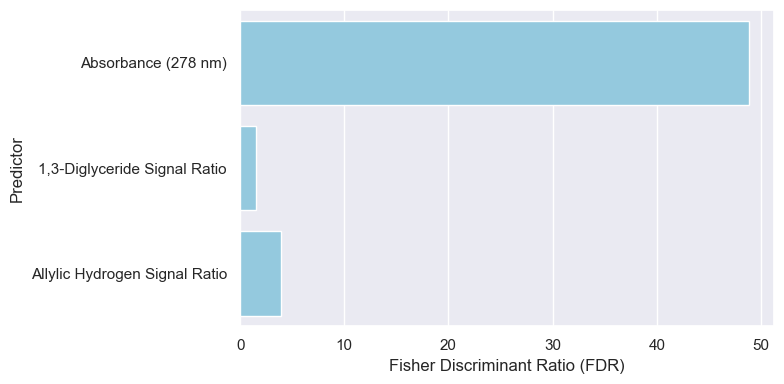

In [33]:
table_raw_feature_importance_scores_nb = pd.DataFrame({
    "Predictor":X_train_NB.columns.tolist(),
    "Fisher Discriminant Ratio":all_fdr
})

plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_raw_feature_importance_scores_nb,
    x="Fisher Discriminant Ratio",
    y="Predictor",
    color="skyblue"
)

plt.xlabel("Fisher Discriminant Ratio (FDR)")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

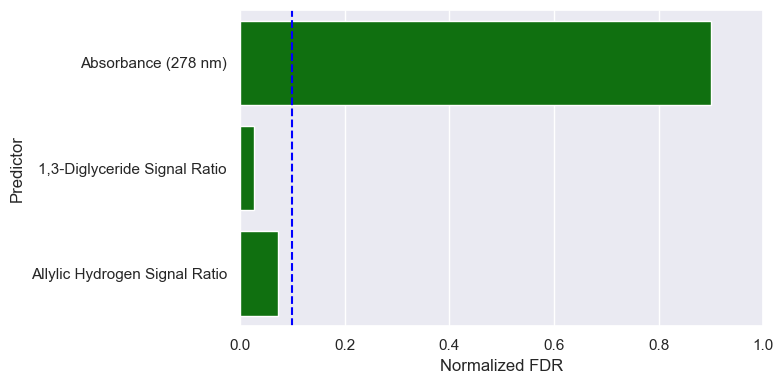

In [34]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_feature_importance_scores_nb,
    x="Normalized Feature Importance Metric (NB)",
    y="Predictor",
    color="green"
)

plt.xlabel("Normalized FDR")
plt.axvline(x = 0.10, color = "blue", linestyle = "--", label = "Cutoff")
plt.ylabel("Predictor")
plt.xlim(0, 1)
plt.xticks()

plt.tight_layout()
plt.show()

We now move to ensemble classifiers. The most popular among them is Random Forest.

Best parameters for RF: {'criterion': 'gini', 'max_depth': 1, 'max_features': None, 'n_estimators': 3}
Best Cross-Validated F1-Score: 100.0%


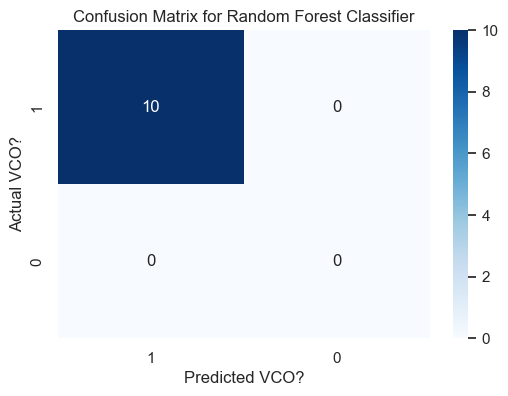

Precision for Random Forest Classifier : 100.0%
Recall for Random Forest Classifier : 100.0%
F1-Score for Random Forest Classifier : 100.0%


In [35]:
X_rf_train = X_dt_train
y_rf_train = y_dt_train
X_rf_test = X_dt_test
y_rf_test = y_dt_test

random_forest = RandomForestClassifier(random_state = 42)

param_grid_rf = {
    "criterion": ["gini", "entropy"],
    "n_estimators": [3, 4, 5, 10],
    "max_features": [None], # We have ONLY three predictors
    "max_depth":[1, 2, 3]
}

grid_search_rf = GridSearchCV(
    estimator = random_forest,
    param_grid = param_grid_rf,
    scoring = "f1",
    cv = skf_cv,
    n_jobs = 6
)

grid_search_rf.fit(X_rf_train, y_rf_train)

best_rf_model = grid_search_rf.best_estimator_
best_rf_params = grid_search_rf.best_params_
best_rf_score = grid_search_rf.best_score_

print(f"Best parameters for RF: {grid_search_rf.best_params_}")
print(f"Best Cross-Validated F1-Score: {round(best_rf_score*100, 2)}%")


y_rf_pred = grid_search_rf.best_estimator_.predict(X_rf_test)
cm_rf = confusion_matrix(y_rf_test, y_rf_pred, labels = [1, 0])
classes = [1, 0]
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted VCO?")
plt.ylabel("Actual VCO?")
plt.title("Confusion Matrix for Random Forest Classifier")
plt.show()

print(f"Precision for Random Forest Classifier : {round(performance_metrics(cm_rf)[0], 2)}%")
print(f"Recall for Random Forest Classifier : {round(performance_metrics(cm_rf)[1], 2)}%")
print(f"F1-Score for Random Forest Classifier : {round(performance_metrics(cm_rf)[2], 2)}%")

In [36]:
feature_importance_scores_rf = best_rf_model.feature_importances_

## Normalize feature importance scores
normalized_feature_importance_scores_rf = feature_importance_scores_rf / np.sum(np.abs(feature_importance_scores_rf))

table_feature_importance_scores_rf_raw = pd.DataFrame({
    "Predictor":X_rf_train.columns,
    "Feature Importance Score (Random Forest)":best_rf_model.feature_importances_
})

table_feature_importance_scores_rf = pd.DataFrame({
    "Predictor":X_rf_train.columns,
    "Normalized Feature Importance Metric (Random Forest)":normalized_feature_importance_scores_rf
})

table_feature_importance_scores_rf

,Predictor,Normalized Feature Importance Metric (Random Forest)
0,Absorbance (278 nm),1.0
1,"1,3-Diglyceride Signal Ratio",0.0
2,Allylic Hydrogen Signal Ratio,0.0


plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_feature_importance_scores_rf,
    x="Normalized Feature Importance Metric (Random Forest)",
    y="Predictor",
    color="steelblue"
)

plt.xlabel("NFIM (Random Forest)")
plt.ylabel("Predictor")
plt.xticks()
plt.axvline(x = 0.1, color = "blue", linestyle = "--", label = "Cutoff")

plt.tight_layout()
plt.show()

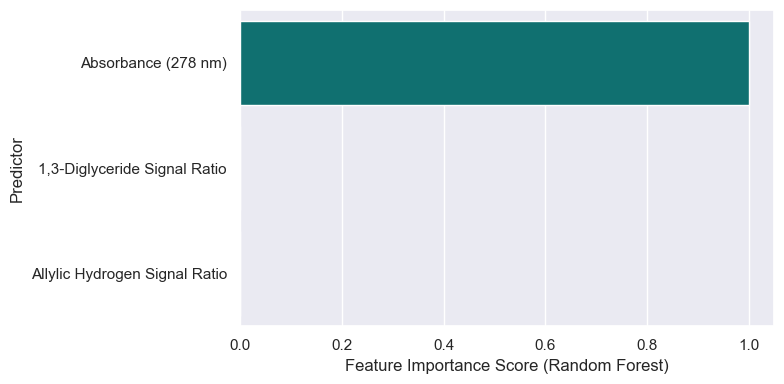

In [40]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=table_feature_importance_scores_rf_raw,
    x="Feature Importance Score (Random Forest)",
    y="Predictor",
    color="teal"
)

plt.xlabel("Feature Importance Score (Random Forest)")
plt.ylabel("Predictor")

plt.tight_layout()
plt.show()

## REFERENCES

(1) Dayrit, F.; Tantengco, G.; Opao, P. G. Proposed Physicochemical Standards for the Identity and Quality Characteristics of Philippine Virgin Coconut Oil. Philipp J Sci 2022, 151 (4). https://doi.org/10.56899/151.04.01. <br>
(2) Dayrit, F. M.; Buenafe, O. E. M.; Chainani, E. T.; De Vera, I. M. S. Analysis of Monoglycerides, Diglycerides, Sterols, and Free Fatty Acids in Coconut ( Cocos Nucifera L.) Oil by31 P NMR Spectroscopy. J. Agric. Food Chem. 2008, 56 (14), 5765–5769. https://doi.org/10.1021/jf8005432. <br>
(3) Kumar, R.; Bansal, V.; Tiwari, A. K.; Sharma, M.; Puri, S. K.; Patel, M. B.; Sarpal, A. S. Estimation of Glycerides and Free Fatty Acid in Oils Extracted From Various Seeds from the Indian Region by NMR Spectroscopy. J Americ Oil Chem Soc 2011, 88 (11), 1675–1685. https://doi.org/10.1007/s11746-011-1846-4.
<br>
(4) Mannina, L.; D’Imperio, M.; Capitani, D.; Rezzi, S.; Guillou, C.; Mavromoustakos, T.; Vilchez, M. D. M.; Fernández, A. H.; Thomas, F.; Aparicio, R. 1 H NMR-Based Protocol for the Detection of Adulterations of Refined Olive Oil with Refined Hazelnut Oil. J. Agric. Food Chem. 2009, 57 (24), 11550–11556. https://doi.org/10.1021/jf902426b.
 <br>
(5) Mavlanov, U.; Atajanov, S.; Nuriddinov, S.; Salimovich, S. S.; Bozorov, S.; Czaja, T. P.; Khakimov, B. Validation of Benchtop NMR-Based Quantification of Saturated, Monounsaturated, and Polyunsaturated Fatty Acids in Edible Oils. Journal of Food Composition and Analysis 2026, 150, 108897. https://doi.org/10.1016/j.jfca.2026.108897. <br>
(6) Gokul Raj, M. R.; Priya Rani, M.; Rameshkumar, K. B. Detection of Coconut Oil Adulteration with Palm Oil through NMR Spectroscopic Method. Grasas aceites 2024, 75 (2), 2012. https://doi.org/10.3989/gya.0861231.2012. 
